# Assignment Task 2: Visualise Data Insights using Seaborn (15 marks)

### Import libraries and load data (1 mark)


In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("bidadari_resort_bookings.csv")
df.head()

,ID,Nationality,Age,DaysSinceCreation,arrival_date_year,arrival_date_month,AverageLeadTime,Revenue,OtherRevenue,BookingsCanceled,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
0,1.0,PRT,51.0,150.0,2016,July,45.0,371.0,105.3,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,PRT,NaN,1095.0,2016,July,61.0,280.0,53.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.0,FRA,60.0,1095.0,2016,July,93.0,240.0,60.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,6.0,JPN,54.0,1095.0,2016,July,58.0,230.0,24.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8.0,FRA,32.0,1095.0,2016,July,38.0,535.0,94.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


### Sub Task 1: Visualise Distribution of Revenue using Seaborn Histogram (1 mark)

Build a histogram of lodging revenue with Seaborn. Filter your data to rows where Revenue is less than 2000. 

<AxesSubplot:xlabel='Revenue', ylabel='Count'>

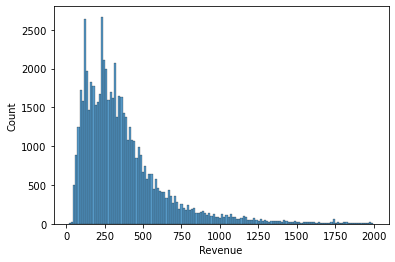

In [3]:
sns.histplot(data=df.Revenue[df.Revenue < 2000])

### Sub Task 2: Create a Bar Chart (2 marks)

Create a horizontal bar chart plotting the average room nights stayed for selected 5 nationalities ("DEU", "FRA", "PRT", "GBR", "ESP"). Change the color palette to "husl".

In [4]:
nations = ["DEU", "FRA", "PRT", "GBR", "ESP"]


nations5 = df[df['Nationality'].isin(nations)]


averagenights = nations5.groupby('Nationality')['RoomNights'].mean().reset_index()
totalrevenue = nations5.groupby('Nationality')['Revenue'].sum().reset_index()

revnights = totalrevenue.join(averagenights.set_index('Nationality'), on='Nationality')
sortednights = revnights.sort_values(by=['Revenue'])
sortednights

,Nationality,Revenue,RoomNights
1,ESP,1475909.33,2.763868
3,GBR,2693123.61,3.171263
4,PRT,2715008.72,2.557056
0,DEU,3113382.55,3.336588
2,FRA,3809315.59,3.305606


<AxesSubplot:xlabel='RoomNights', ylabel='Nationality'>

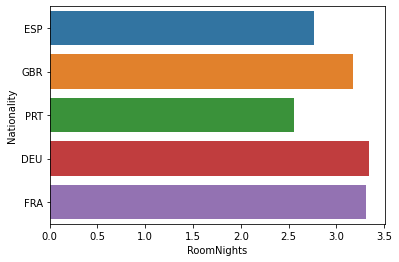

In [5]:
sns.barplot(x=sortednights.RoomNights, y=sortednights.Nationality, orient='h')

### Sub Task 3: Create a Box Plot (1 mark)

Create a single boxplot of Revenue for the selected 5 countries, where nightly revenue is less than 2000.


In [6]:
nations5.columns

Index(['ID', 'Nationality', 'Age', 'DaysSinceCreation', 'arrival_date_year',
       'arrival_date_month', 'AverageLeadTime', 'Revenue', 'OtherRevenue',
       'BookingsCanceled', 'BookingsNoShowed', 'BookingsCheckedIn',
       'PersonsNights', 'RoomNights', 'DaysSinceLastStay',
       'DaysSinceFirstStay', 'DistributionChannel', 'MarketSegment',
       'SRHighFloor', 'SRLowFloor', 'SRAccessibleRoom', 'SRMediumFloor',
       'SRBathtub', 'SRShower', 'SRCrib', 'SRKingSizeBed', 'SRTwinBed',
       'SRNearElevator', 'SRAwayFromElevator', 'SRNoAlcoholInMiniBar',
       'SRQuietRoom'],
      dtype='object')

<AxesSubplot:xlabel='Revenue'>

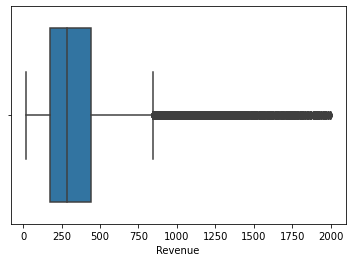

In [7]:
lessthan = nations5[nations5.Revenue < 2000].reset_index()
sns.boxplot(data=lessthan, x="Revenue")

### Sub Task 4: Create ViolinPlots ( 2 marks)

1. Create a chart that has one violinplot for each nationality. Look at these plots both without a filter and with  revenue filtered to less than 2000 and number of nights is less than 10 nights.
2. Create a violinplot for the age distribution for each of the selected 5 nationalities

In [8]:
lessthan2k = df['Revenue'] < 2000
nights10 = df['RoomNights'] < 10

countnations = df['Nationality'].value_counts().reset_index()

<AxesSubplot:xlabel='Nationality', ylabel='Revenue'>

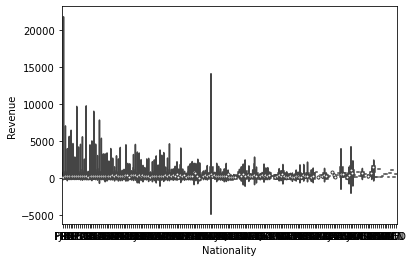

In [9]:
sns.violinplot(data=df, x="Nationality", y='Revenue')

<AxesSubplot:xlabel='Nationality', ylabel='Revenue'>

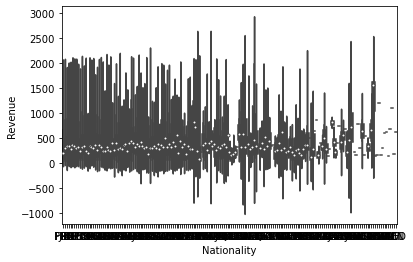

In [10]:
sns.violinplot(x="Nationality", y='Revenue', data=df[lessthan2k & nights10])

Age distribution for the 5 nations

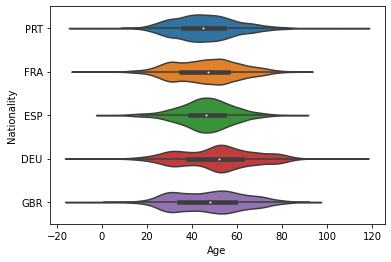

In [11]:
sns.violinplot(data=nations5, x="Age", y="Nationality")
plt.xlabel('Age')
plt.show()

### Sub Task 5: Linear Relationship Plots (2 marks)

1. Create a regression plot comparing Revenue as y and RoomNights as x for rows in 5 selected countries.
2. Modify the regresssion plot and use different colour line to represent the 5 nationalities. Which nationality appears to pay the most per night for customers with  revenue filtered is less than 2000 and number of nights is less than 10 nights ? Indicate your answer using Markdown cell.


<AxesSubplot:xlabel='Revenue', ylabel='RoomNights'>

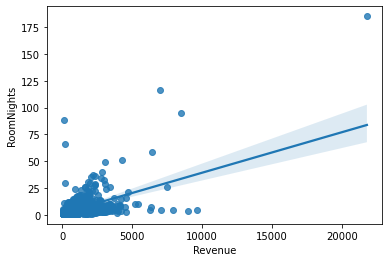

In [12]:
sns.regplot(data=nations5, x='Revenue', y='RoomNights')

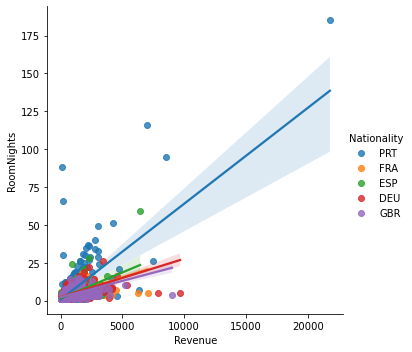

In [13]:
sns.lmplot(data=nations5, x='Revenue', y='RoomNights', hue='Nationality')

C:\Users\zoe\AppData\Local\Temp/ipykernel_13268/1079707913.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  filtered = nations5[lessthan2k | nights10].reset_index()


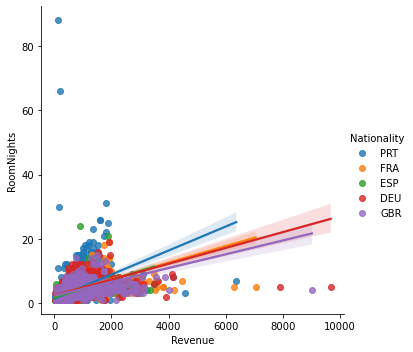

In [15]:
lessthan2k = df['Revenue'] < 2000
nights10 = df['RoomNights'] < 10

filtered = nations5[lessthan2k | nights10].reset_index()

sns.lmplot(data=filtered, x='Revenue', y='RoomNights', hue='Nationality')

After filtering, It is evident that GBR, Great Britian pay the most per night, as they have high revenue while having the lowest number of nights occupied.

### Sub Task 6: Create a Pairplot (2 marks)

Create a pairplot with the columns: Age, Revenue, OtherRevenue, PersonsNights, RoomNights and DaysSinceLastStay

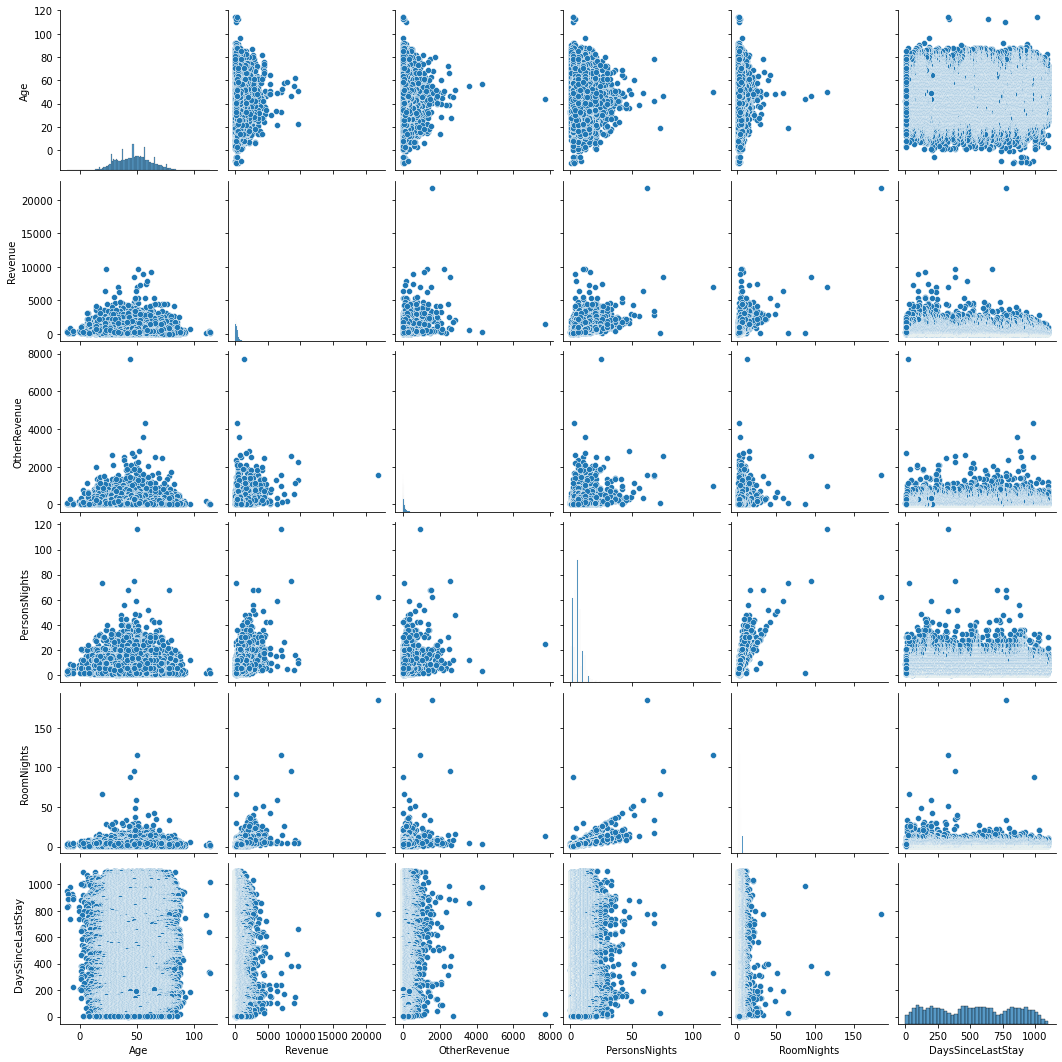

In [16]:
# using 5nations filter

paircols = ['Age', 'Revenue', 'OtherRevenue', 'PersonsNights', 'RoomNights' , 'DaysSinceLastStay']
pairplot = df[paircols]

sns.pairplot(pairplot)

### Sub Task 7: Create Heatmap (2 marks)

1. Using the 5 selected countries DataFrame, create a heatmap of Nationality as rows and MarketSegment as columns with the mean value of Revenue in each cell.
2. Create a heatmap of the correlation matrix created when using the .corr() method on the transactions dataframe. Use the 'vlag' color palette.

<AxesSubplot:xlabel='MarketSegment', ylabel='Nationality'>

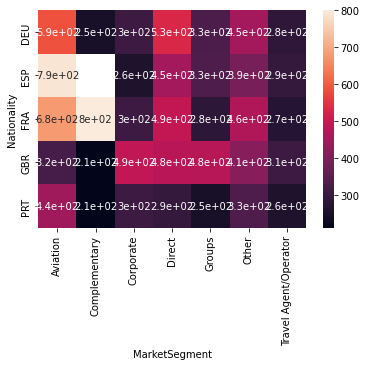

In [17]:
import numpy as np
maps = pd.pivot_table(nations5, index='Nationality', columns='MarketSegment', values='Revenue', aggfunc=np.mean)
sns.heatmap(maps, annot=True)

C:\Users\zoe\AppData\Local\Temp/ipykernel_13268/2598846593.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  matrix = df.corr()


<AxesSubplot:>

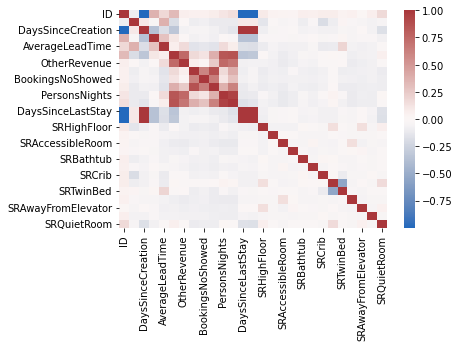

In [18]:

matrix = df.corr()
sns.heatmap(matrix.corr(), cmap = 'vlag')

### Sub Task 8: Conclusion (2 marks)

Summarise your data exploratory task in one or 2 paragraph(s)
